In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
def f(x):
  return 3*x**2 - 4*x + 5

In [7]:
f(3.0)

20.0

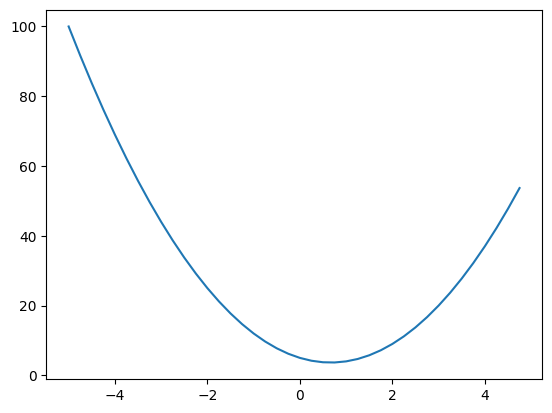

In [12]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
ys
plt.plot(xs,ys)

In [22]:
h = 0.000000001
x = -3.0
(f(x + h) - f(x))/h

-22.000001820288162

In [23]:

a = 2.0
b = -3.0
c = 10.0
d = a *b + c
print(d)

4.0


In [24]:
h = 0.000001

a = 2.0
b = -3.0
c = 10.0

d1 = a *b + c
a += h
d2 = a*b+c
print('d1',d1)
print('d2',d2)
print('slope',(d2-d1)/h)

d1 4.0
d2 3.9999969999999996
slope -3.000000000419334


In [209]:
class Value:
  def __init__(self,data, _children=(), _op='',label = ''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self,other):
    other = other if isinstance(other,Value) else Value(other)
    out = Value(self.data + other.data, (self,other),'+')
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __radd__(self,other):
    return self + other

  def __mul__(self,other):
    other = other if isinstance(other,Value) else Value(other)
    out = Value(self.data * other.data, (self,other),'*')
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
    return out

  def __pow__(self,other):
    assert isinstance(other,(int,float)),"only supporting int/float powers for now"
    out = Value(self.data**other,(self,),f'**{other}')

    def _backward():
      self.grad += (other * self.data**(other-1)) * out.grad
    out._backward = _backward
    return out

  def __rmul__(self,other):
    return self * other

  def __truediv__(self,other):
    return self * other**-1

  def __neg__(self):
    return self * -1

  def __sub__(self,other):
    return self + (-other)

  def exp(self):
    x = self.data
    out = Value(math.exp(x),(self,),'exp')
    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t,(self,),'tanh')
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10.0,label='c')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label ='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [164]:
a = Value(2.0)
b = Value(4.0)
a / b

Value(data=0.5)

In [110]:
from graphviz import Digraph

def trace(root):
  nodes,edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes,edges

def draw_dot(root):
  dot = Digraph(format='svg',graph_attr={'rankdir':'LR'})
  nodes,edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    dot.node(name=uid,label="{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad),shape='record')
    if n._op:
      dot.node(name = uid + n._op,label=n._op)
      dot.edge(uid + n._op,uid)

  for n1,n2 in edges:
    dot.edge(str(id(n1)),str(id(n2)) + n2._op)

  return dot



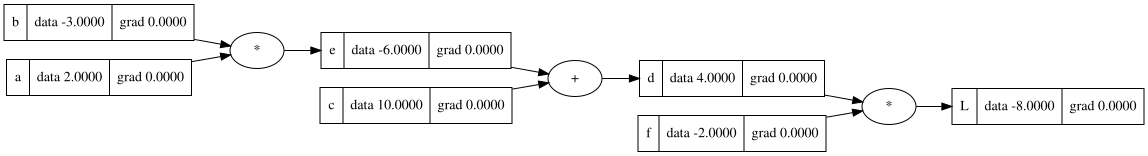

In [128]:
draw_dot(L)

In [85]:
f.grad = 4.0
d.grad = -2.0

In [86]:
c.grad = -2.0
e.grad = -2.0

In [87]:
a.grad = (-2.0 * -3.0)
b.grad = (-2.0 * 2.0)

In [88]:
L.grad = 1.0

In [89]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f
print(L.data)

-7.286496


In [67]:
def lol():
  h = 0.001

  a = Value(2.0,label='a')
  b = Value(-3.0,label='b')
  c = Value(10.0,label='c')
  e = a * b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label ='f')
  L = d * f; L.label = 'L'
  L1 = L.data

  a = Value(2.0,label='a')
  b = Value(-3.0,label='b')
  c = Value(10.0,label='c')
  e = a * b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label ='f')
  L = d * f; L.label = 'L'
  L2 = L.data

  print((L2 - L1)/h)

lol()

-2.000000000000668


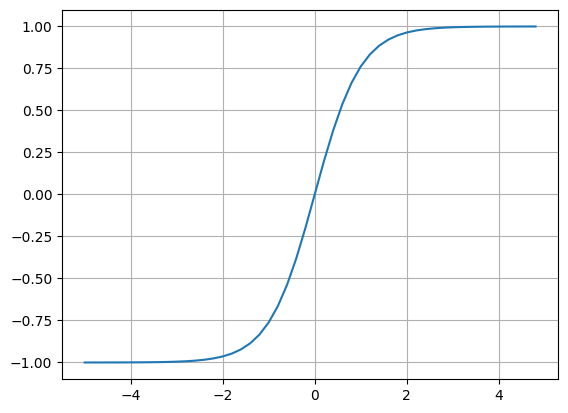

In [91]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)))
plt.grid();

In [166]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
draw_dot(o)

AttributeError: 'Value' object has no attribute 'tanh'

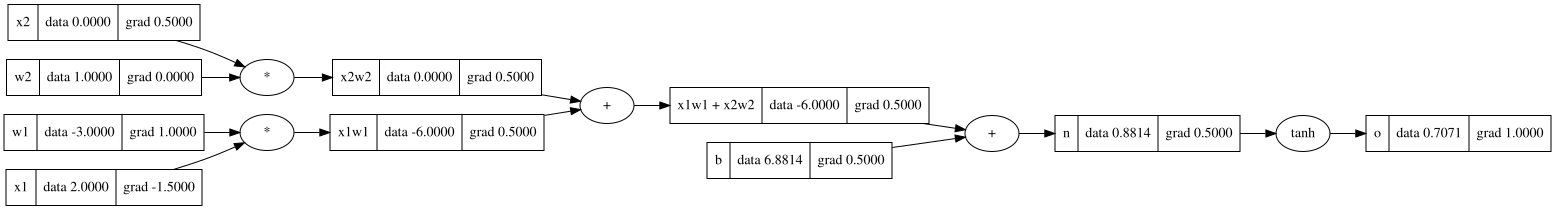

In [145]:
# 전체 backward 실행을 위해 o.backward() 호출
o.backward()
# 업데이트된 gradient가 포함된 시각화 출력
draw_dot(o)

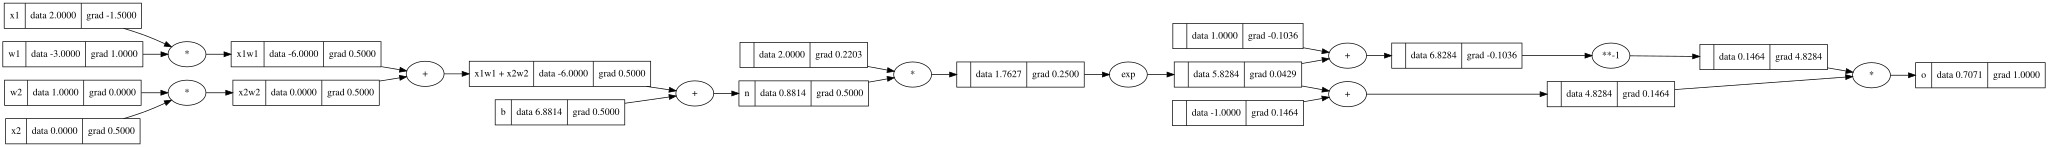

In [167]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp()
o = (e - 1) / (e + 1); o.label = 'o'
o.backward()
draw_dot(o)

In [172]:
import torch

x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2',x2.grad.item())
print('w2',w2.grad.item())
print('x1',x1.grad.item())
print('w1',w1.grad.item())


0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [170]:
torch.Tensor([[1,2,3],[4,5,6]])

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [371]:
import random
class Neuron:
  def __init__(self,nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  def  __call__(self,x):
    # w * x + b
    act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self,nin,nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self,x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [ p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self,nin,nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

  def __call__(self,x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]



In [372]:
x = [2.0, 3.0, -1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data=-0.05426710738474913)

In [366]:
n.parameters()

[Value(data=-0.7712831060076177),
 Value(data=-0.2793244825258001),
 Value(data=-0.8215605957436829),
 Value(data=-0.1360937539788598),
 Value(data=-0.7893910482188442),
 Value(data=0.5002013157046434),
 Value(data=-0.3155666949287279),
 Value(data=-0.7349809396188496),
 Value(data=0.20413819112451081),
 Value(data=-0.33079701813140616),
 Value(data=0.8732171910444535),
 Value(data=0.0791319686698948),
 Value(data=-0.6863860011493945),
 Value(data=-0.5966976230287386),
 Value(data=-0.21585408561620723),
 Value(data=0.15781638505722317),
 Value(data=0.3590469290040077),
 Value(data=0.5496117441329584),
 Value(data=-0.33499332286066186),
 Value(data=-0.5412916124317257),
 Value(data=-0.3313897128414489),
 Value(data=0.15694032798687774),
 Value(data=-0.6665774766818635),
 Value(data=-0.47943725948565197),
 Value(data=0.8051378978030188),
 Value(data=0.0851073534915654),
 Value(data=-0.8778777675838636),
 Value(data=-0.15887896123998102),
 Value(data=-0.3048660825490157),
 Value(data=-0.4

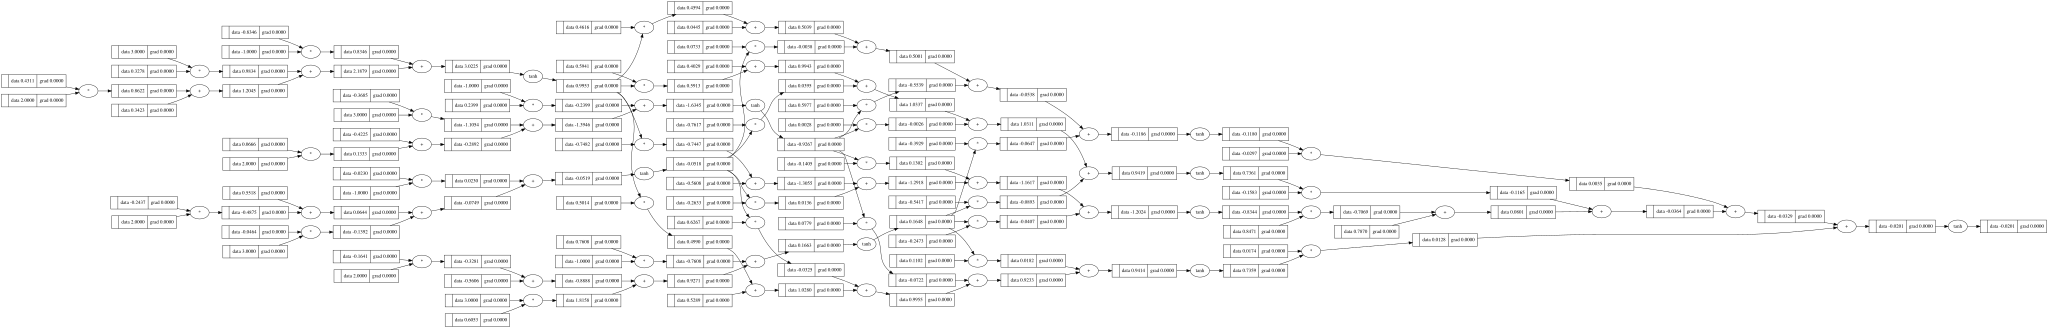

In [192]:
draw_dot(n(x))

In [367]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0]
]
ys = [1.0,-1.0,-1.0,1.0] # desired targets

ypred = [n(x) for x in xs]
ypred

[Value(data=-0.5804739552679303),
 Value(data=-0.843850670691103),
 Value(data=-0.8121761839670716),
 Value(data=-0.3855952257172119)]

In [354]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys,ypred))
loss

Value(data=7.999999999999819)

In [355]:
loss.backward()

In [356]:
n.layers[0].neurons[0].w[0].grad

85.21191188870277

In [357]:
n.layers[0].neurons[0].w[0].data

-6.022179919730743

In [358]:
for p in n.parameters():
  p.data += -0.001 * p.grad

In [359]:
n.layers[0].neurons[0].w[0].data

-6.107391831619445

In [360]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys,ypred))
loss

Value(data=7.999999999999886)

In [361]:
ypred

[Value(data=0.9999999999999859),
 Value(data=0.9999999999999859),
 Value(data=0.9999999999999859),
 Value(data=0.9999999999999859)]

In [376]:
for k in range(10):
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys,ypred))
  for p in n.parameters():
    p.grad = 0.0

  # backward pass
  loss.backward()

  # update
  for p in n.parameters():
    p.data += -0.05 * p.grad

  print(k,loss.data)

0 0.027366623684209376
1 0.02630597853755768
2 0.025321675868271755
3 0.02440586678121971
4 0.023551735265300293
5 0.02275333442682434
6 0.022005452833021785
7 0.021303504712729668
8 0.02064343920019386
9 0.02002166488519802


In [369]:
ypred

[Value(data=0.9989444084964189),
 Value(data=-0.9997477938711323),
 Value(data=-0.9997677189009399),
 Value(data=0.9994507581681297)]